In [10]:
import pandas as pd
import matplotlib.pyplot as plt

visits = pd.read_csv("../data/raw/air_visit_data.csv", parse_dates=["visit_date"])
visits.head()

,air_store_id,visit_date,visitors
0,air_ba937bf13d40fb24,2016-01-13,25
1,air_ba937bf13d40fb24,2016-01-14,32
2,air_ba937bf13d40fb24,2016-01-15,29
3,air_ba937bf13d40fb24,2016-01-16,22
4,air_ba937bf13d40fb24,2016-01-18,6


In [2]:
visits.shape

(252108, 3)

In [3]:
visits.info()

<class 'pandas.DataFrame'>
RangeIndex: 252108 entries, 0 to 252107
Data columns (total 3 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   air_store_id  252108 non-null  str           
 1   visit_date    252108 non-null  datetime64[us]
 2   visitors      252108 non-null  int64         
dtypes: datetime64[us](1), int64(1), str(1)
memory usage: 5.8 MB


In [4]:
visits.isna().sum()

air_store_id    0
visit_date      0
visitors        0
dtype: int64

basic facts

In [5]:
print("Date range:", visits["visit_date"].min(), "to", visits["visit_date"].max())
print("Number of restaurants:", visits["air_store_id"].nunique())
visits["visitors"].describe()

Date range: 2016-01-01 00:00:00 to 2017-04-22 00:00:00
Number of restaurants: 829


count    252108.000000
mean         20.973761
std          16.757007
min           1.000000
25%           9.000000
50%          17.000000
75%          29.000000
max         877.000000
Name: visitors, dtype: float64

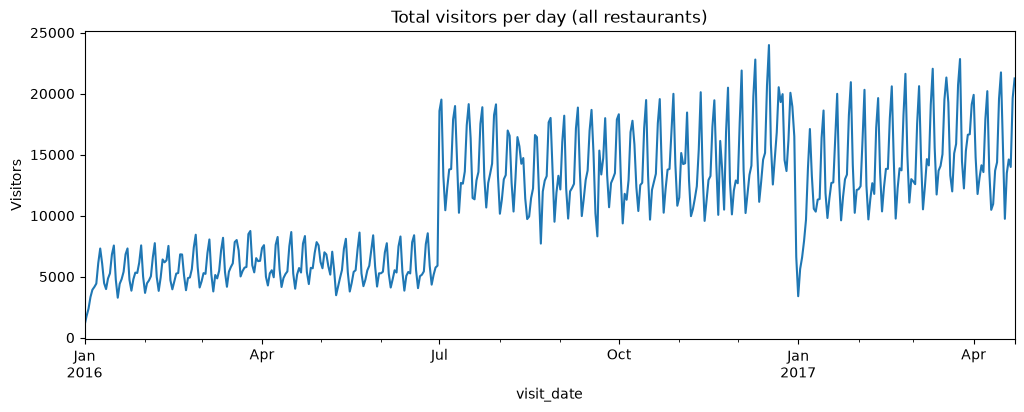

In [6]:
daily = visits.groupby("visit_date")["visitors"].sum()
daily.plot(figsize=(12, 4), title="Total visitors per day (all restaurants)")
plt.ylabel("Visitors")
plt.show()

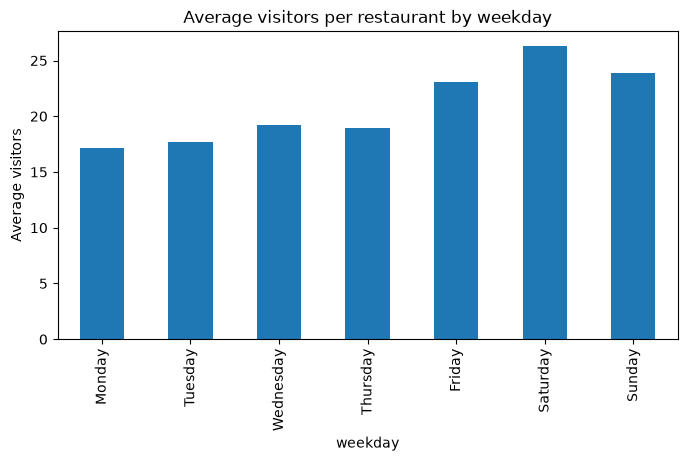

In [7]:
visits["weekday"] = visits["visit_date"].dt.day_name()
order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
avg_weekday = visits.groupby("weekday")["visitors"].mean().reindex(order)
avg_weekday.plot(kind="bar", figsize=(8, 4), title="Average visitors per restaurant by weekday")
plt.ylabel("Average visitors")
plt.show()

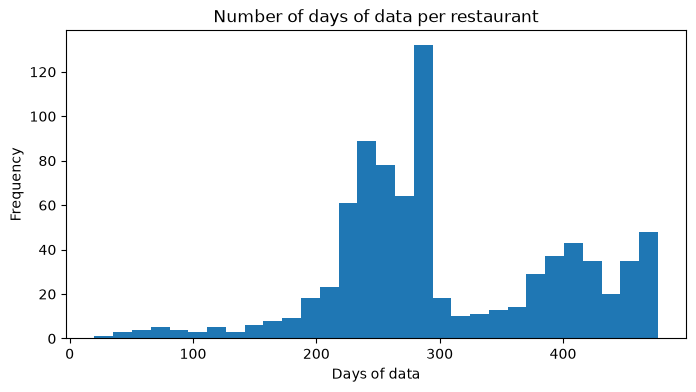

In [8]:
rows_per_store = visits.groupby("air_store_id").size()
rows_per_store.plot(kind="hist", bins=30, figsize=(8, 4), title="Number of days of data per restaurant")
plt.xlabel("Days of data")
plt.show()

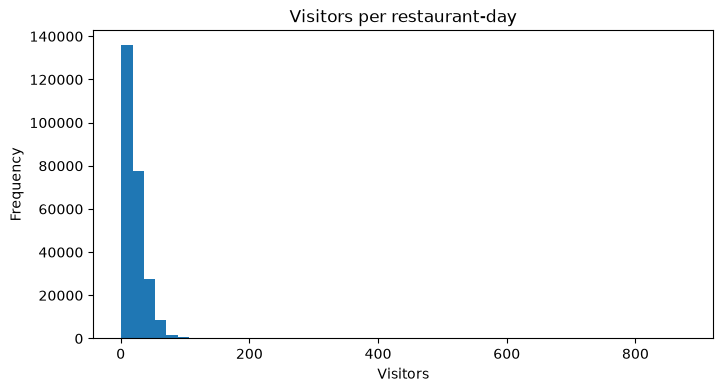

In [9]:
visits["visitors"].plot(kind="hist", bins=50, figsize=(8, 4), title="Visitors per restaurant-day")
plt.xlabel("Visitors")
plt.show()

The weekend is generally more busier than the rest of the week. Saturdays are the most busy, while weekdays on average have almost the same amount of people everyday. There were quite some flunctuations, however the greatest increase was in july from 5000-12/13000. There was also a massive drop in Jan 2017, howver the business recovered so it was an anamoly.